In [4]:

import pandas as pd
df = pd.read_csv('/content/SampleSuperstore.csv')
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [5]:

# Dataset mein kitni rows aur columns hain?
print("Dataset Shape:", df.shape)

# Sabhi column names dekho
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset ki basic information dekho
print("\nDataset Information:")
df.info()

Dataset Shape: (9994, 13)

Column Names:
['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object

In [6]:

# 1. Missing values check karo
print("Missing Values:")
print(df.isnull().sum())

# 2. Duplicate rows check karo
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64

Duplicate Rows:
17


In [7]:

# Remove duplicate rows
df = df.drop_duplicates()

# Check dataset after cleaning
print("Dataset after removing duplicates:", df.shape)

# Verify duplicates
print("Duplicate rows remaining:", df.duplicated().sum())


Dataset after removing duplicates: (9977, 13)
Duplicate rows remaining: 0


In [8]:

# Calculate total sales and profit
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))


Total Sales: 2296195.59
Total Profit: 286241.42


In [9]:

# Calculate sales for each category
category_sales = df.groupby('Category')['Sales'].sum()

# Display category-wise sales
print(category_sales)

# Find category with highest sales
print("\nCategory with Highest Sales:")
print(category_sales.idxmax())


Category
Furniture          741306.3133
Office Supplies    718735.2440
Technology         836154.0330
Name: Sales, dtype: float64

Category with Highest Sales:
Technology


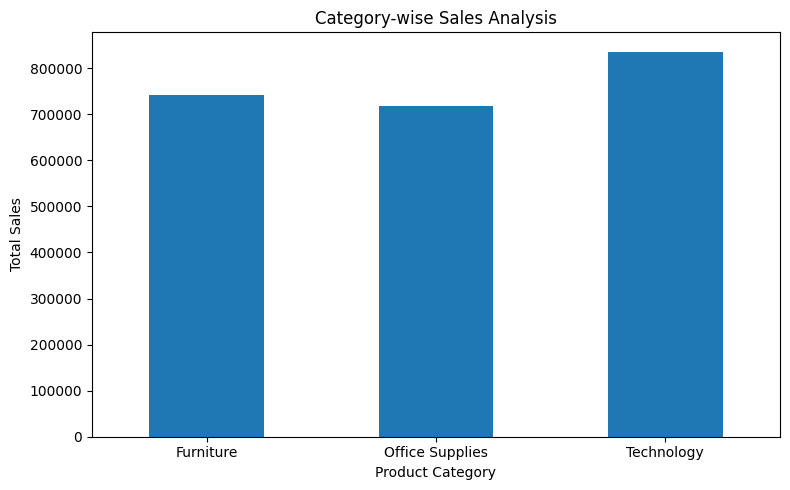

In [10]:

import matplotlib.pyplot as plt

# Calculate category-wise sales
category_sales = df.groupby('Category')['Sales'].sum()

# Create bar graph
plt.figure(figsize=(8, 5))
category_sales.plot(kind='bar')

plt.title('Category-wise Sales Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [11]:

# Calculate sales for each region
region_sales = df.groupby('Region')['Sales'].sum()

# Display sales values
print("Region-wise Sales:")
print(region_sales)

# Find the region with highest sales
print("\nRegion with Highest Sales:")
print(region_sales.idxmax())


Region-wise Sales:
Region
Central    500782.8528
East       678435.1960
South      391721.9050
West       725255.6365
Name: Sales, dtype: float64

Region with Highest Sales:
West


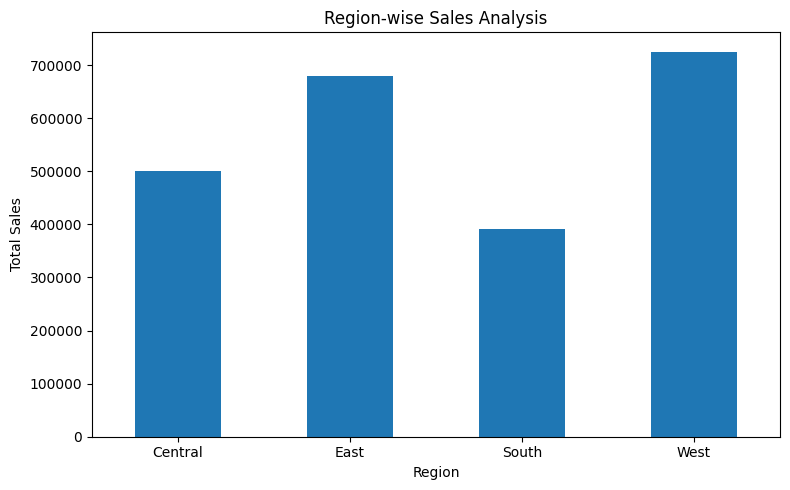

In [13]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
region_sales.plot(kind='bar')

plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [12]:

# Calculate profit by sub-category
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

# Sort profit from highest to lowest
top_5_profit = subcategory_profit.sort_values(ascending=False).head(5)

print("Top 5 Profitable Sub-Categories:")
print(top_5_profit)


Top 5 Profitable Sub-Categories:
Sub-Category
Copiers        55617.8249
Phones         44515.7306
Accessories    41936.6357
Paper          33944.2395
Binders        30228.0003
Name: Profit, dtype: float64


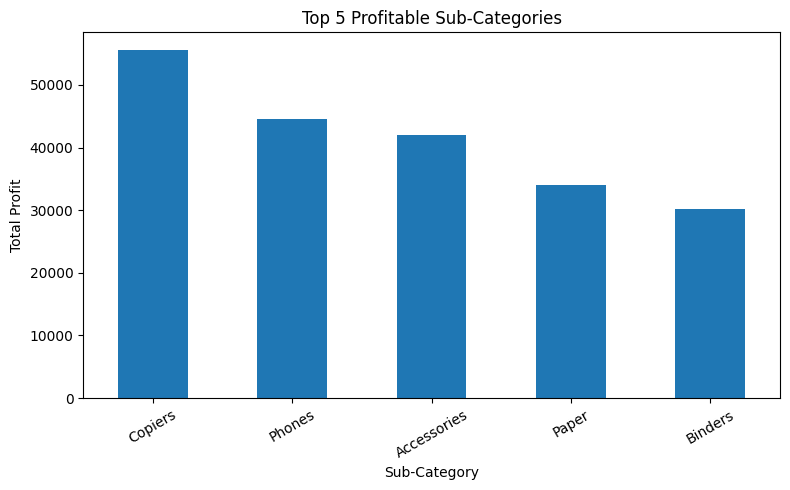

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
top_5_profit.plot(kind='bar')

plt.title('Top 5 Profitable Sub-Categories')
plt.xlabel('Sub-Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [15]:
print(df.columns.tolist())

['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount', 'Profit']


In [16]:

# Group data by discount
discount_analysis = df.groupby('Discount').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).round(2)

print("Discount-wise Sales and Profit:")
print(discount_analysis)


Discount-wise Sales and Profit:
               Sales     Profit
Discount                       
0.00      1087277.56  320844.41
0.10        54369.35    9029.18
0.15        27558.52    1418.99
0.20       764504.94   90306.61
0.30       102945.28  -10357.22
0.32        14493.46   -2391.14
0.40       116417.78  -23057.05
0.45         5484.97   -2493.11
0.50        58918.54  -20506.43
0.60         6644.70   -5944.66
0.70        40620.28  -40075.36
0.80        16960.19  -30532.80


In [17]:

# Final Sales Data Analysis Insights

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_quantity = df['Quantity'].sum()

category_sales = df.groupby('Category')['Sales'].sum()
region_sales = df.groupby('Region')['Sales'].sum()
subcategory_profit = df.groupby('Sub-Category')['Profit'].sum()

print("===== FINAL PROJECT INSIGHTS =====")
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)

print("\nHighest Sales Category:", category_sales.idxmax())
print("Highest Sales Region:", region_sales.idxmax())
print("Most Profitable Sub-Category:", subcategory_profit.idxmax())
print("Least Profitable Sub-Category:", subcategory_profit.idxmin())


===== FINAL PROJECT INSIGHTS =====
Total Sales: 2296195.59
Total Profit: 286241.42
Total Quantity Sold: 37820

Highest Sales Category: Technology
Highest Sales Region: West
Most Profitable Sub-Category: Copiers
Least Profitable Sub-Category: Tables



## Final Conclusion

This project analyzes sales data using Python, Pandas, and Matplotlib.

1. Total Sales: 2,296,195.59
2. Total Profit: 286,241.42
3. Total Quantity Sold: 37,820 units
4. Highest Sales Category: Technology
5. Highest Sales Region: West
6. Most Profitable Sub-Category: Copiers
7. Least Profitable Sub-Category: Tables

The analysis helps identify profitable categories and areas for business improvement.
